In [15]:
!pip install pandas numpy scipy matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import trim_mean
from scipy.stats import median_abs_deviation

plt.style.use('ggplot')

# LOAD DATASET

In [16]:
column_names = [
    'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM',
    'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO',
    'B', 'LSTAT', 'MEDV'
]

df = pd.read_csv("housing.csv", header=None, names=column_names)

df.head()


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


# DATASET INFORMATION

In [ ]:
#| Variable | Description                                                     | Data Category    |
#| CRIM     | Per capita crime rate                                           | Continuous       |
#| ZN       | Proportion of residential land zoned                            | Continuous       |
#| INDUS    | Proportion of non-retail business acres                         | Continuous       |
#| CHAS     | Charles River dummy variable (0 = No, 1 = Yes)                  | Nominal (Binary) |
#| NOX      | Nitric oxide concentration                                      | Continuous       |
#| RM       | Average number of rooms per dwelling                            | Continuous       |
#| AGE      | Percentage of owner-occupied units built before 1940            | Continuous       |
#| DIS      | Weighted distance to employment centers                         | Continuous       |
#| RAD      | Index of accessibility to radial highways                       | Discrete         |
#| TAX      | Property tax rate                                               | Continuous       |
#| PTRATIO  | Pupil-teacher ratio                                             | Continuous       |
#| B        | Proportion related to the Black population (dataset definition) | Continuous       |
#| LSTAT    | Percentage of lower-status population                           | Continuous       |
#| MEDV     | Median value of owner-occupied homes (Target Variable)          | Continuous       |


In [ ]:
#The Boston Housing Dataset contains information about housing and neighborhood characteristics in different suburbs of Boston. It is widely used for statistical analysis and machine learning to study how various factors influence the median value of owner-occupied homes (MEDV). The dataset consists of 506 observations and 14 variables, including crime rate, average number of rooms, tax rate, pollution level, accessibility to highways, and median house value.

In [17]:
df.info()

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [18]:
numeric_cols = df.select_dtypes(include=np.number).columns
print(numeric_cols)

column = "MEDV"

Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'MEDV'],
      dtype='object')


# Mean

In [19]:
#Mean is the arithmetic average of all observations.

In [20]:
mean_value = df[column].mean()

print("Mean =", mean_value)

Mean = 22.532806324110698


In [ ]:
#The mean and median provide the central tendency of the selected variable. 
#If the mean is close to the median, the data is approximately symmetric; otherwise, it may be skewed.

# Trimmed Mean

In [21]:
#Removes the lowest and highest 10% of values before calculating the mean.

In [22]:
trimmed = trim_mean(df[column].dropna(), 0.10)

print("Trimmed Mean =", trimmed)

Trimmed Mean = 21.562315270935958


In [ ]:
#The trimmed mean is similar to the mean but is less affected by extreme values because it excludes the highest and lowest observations.

# Median

In [23]:
#Median is the middle value after sorting the data.

In [24]:
median_value = df[column].median()

print("Median =", median_value)

Median = 21.2


# Weighted Mean

In [25]:
#Weighted mean assigns different importance (weights) to each observation.

In [27]:
weights = df["RM"]   

weighted_mean = np.average(
    df[column].fillna(df[column].mean()),
    weights=weights
)

print("Weighted Mean =", weighted_mean)

Weighted Mean = 23.24638252843924


In [ ]:
#The weighted mean assigns different importance to observations. When equal weights are used, it is the same as the arithmetic mean.

# Variance

In [ ]:
#Variance measures how spread out the data is from the mean.

In [28]:
variance = df[column].var()

print("Variance =", variance)

Variance = 84.5867235940986


In [ ]:
#Variance indicates how widely the data values are spread around the mean. A larger variance implies greater variability.

# Standard Deviation

In [ ]:
#Standard deviation indicates the average distance of data points from the mean.

In [29]:
std = df[column].std()

print("Standard Deviation =", std)

Standard Deviation = 9.19710408737982


In [ ]:
#The standard deviation measures the average spread of observations around the mean. A higher value indicates more dispersed data.

# Quartile

In [ ]:
#Quartiles divide the data into four equal parts.

In [30]:
Q1 = df[column].quantile(0.25)
Q2 = df[column].quantile(0.50)
Q3 = df[column].quantile(0.75)

print("Q1 =", Q1)
print("Q2 =", Q2)
print("Q3 =", Q3)

Q1 = 17.025
Q2 = 21.2
Q3 = 25.0


# Interquartile Range (IQR)

In [ ]:
#IQR measures the spread of the middle 50% of the data.

In [31]:
IQR = Q3 - Q1

print("IQR =", IQR)

IQR = 7.975000000000001


In [ ]:
#The quartiles divide the data into four equal parts. The Interquartile Range (IQR) measures the spread of the middle 50% of the observations and helps identify outliers.

# Median Absolute Deviation (MAD)

In [ ]:
#MAD is a robust measure of variability based on the median.

In [32]:
mad = median_abs_deviation(df[column].dropna())

print("MAD =", mad)

MAD = 4.0


In [ ]:
#MAD is a robust measure of variability based on the median and is less sensitive to outliers than the standard deviation.

# Minimum and Maximum

In [ ]:
#Minimum: The smallest value in the dataset.
#Maximum: The largest value in the dataset.

In [33]:
# Minimum value
minimum = df[column].min()

# Maximum value
maximum = df[column].max()

print("Minimum =", minimum)
print("Maximum =", maximum)

Minimum = 5.0
Maximum = 50.0


In [ ]:
#The minimum and maximum values represent the smallest and largest observations in the dataset, indicating the overall range.

# PERCENTILES

In [ ]:
#A percentile indicates the value below which a certain percentage of observations fall. For example, the 75th percentile means that 75% of the observations are less than or equal to that value.

In [34]:
percentiles = [10, 20, 25, 30, 40, 50, 60, 70, 75, 80, 90, 95]

for p in percentiles:
    value = np.percentile(df[column].dropna(), p)
    print(f"{p}th Percentile = {value}")

10th Percentile = 12.75
20th Percentile = 15.3
25th Percentile = 17.025
30th Percentile = 18.2
40th Percentile = 19.7
50th Percentile = 21.2
60th Percentile = 22.7
70th Percentile = 24.15
75th Percentile = 25.0
80th Percentile = 28.2
90th Percentile = 34.8
95th Percentile = 43.4


In [ ]:
#The quartiles divide the data into four equal parts. The Interquartile Range (IQR) measures the spread of the middle 50% of the observations and helps identify outliers.

# BOXPLOT

In [ ]:
#Displays the median, quartiles, spread, and potential outliers.

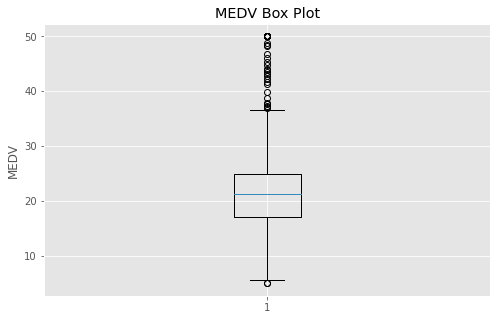

In [35]:
plt.figure(figsize=(8,5))

plt.boxplot(df[column].dropna())

plt.title(f"{column} Box Plot")

plt.ylabel(column)

plt.show()

In [ ]:
#The box plot summarizes the distribution of the data, showing the median, quartiles, spread, and any potential outliers.

# HISTOGRAM

In [ ]:
#Shows how frequently values occur within intervals.

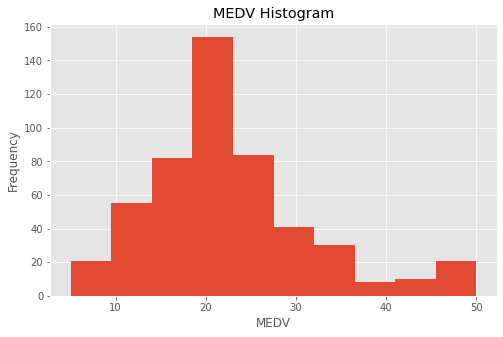

In [36]:
plt.figure(figsize=(8,5))

plt.hist(df[column].dropna(), bins=10)

plt.title(f"{column} Histogram")

plt.xlabel(column)

plt.ylabel("Frequency")

plt.show()

In [ ]:
#The histogram displays the frequency distribution of the selected variable, helping identify the shape of the data (e.g., symmetric, skewed, or multimodal).

# Density Plot

In [ ]:
#Provides a smooth estimate of the data distribution.

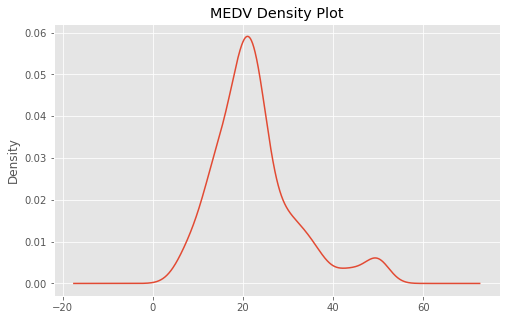

In [37]:
plt.figure(figsize=(8,5))

df[column].dropna().plot(kind='density')

plt.title(f"{column} Density Plot")

plt.show()

In [ ]:
#The density plot provides a smooth estimate of the data distribution and makes it easier to visualize the overall pattern.

# Scatter Plot

In [ ]:
#Shows the relationship between two numerical variables.

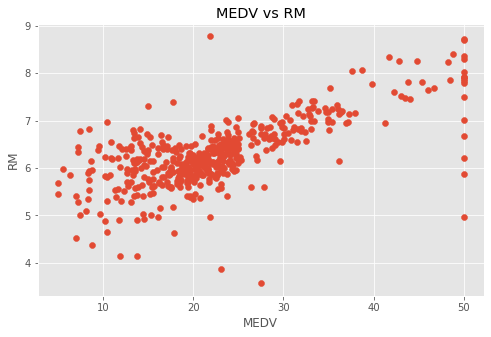

In [39]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["MEDV"],
    df["RM"]
)

plt.xlabel("MEDV")

plt.ylabel("RM")

plt.title("MEDV vs RM")

plt.show()

In [ ]:
The scatter plot illustrates the relationship between two numerical variables and helps identify trends, clusters, or possible correlations.

In [ ]:
#Correleation

# Correlation Heatmap (Without Seaborn)

# Summary

In [40]:
from scipy.stats import trim_mean, median_abs_deviation
import numpy as np

summary = pd.DataFrame({

    'Mean': [df['MEDV'].mean()],

    'Trimmed Mean': [trim_mean(df['MEDV'], 0.10)],

    'Weighted Mean': [np.average(df['MEDV'])],   # Equal weights

    'Median': [df['MEDV'].median()],

    'Minimum': [df['MEDV'].min()],

    'Maximum': [df['MEDV'].max()],

    'Variance': [df['MEDV'].var()],

    'Std Dev': [df['MEDV'].std()],

    'Q1': [df['MEDV'].quantile(0.25)],

    'Q2': [df['MEDV'].quantile(0.50)],

    'Q3': [df['MEDV'].quantile(0.75)],

    'IQR': [df['MEDV'].quantile(0.75) - df['MEDV'].quantile(0.25)],

    '10th Percentile': [df['MEDV'].quantile(0.10)],

    '25th Percentile': [df['MEDV'].quantile(0.25)],

    '50th Percentile': [df['MEDV'].quantile(0.50)],

    '75th Percentile': [df['MEDV'].quantile(0.75)],

    '90th Percentile': [df['MEDV'].quantile(0.90)],

    'MAD': [median_abs_deviation(df['MEDV'])]

})

summary

,Mean,Trimmed Mean,Weighted Mean,Median,Minimum,Maximum,Variance,Std Dev,Q1,Q2,Q3,IQR,10th Percentile,25th Percentile,50th Percentile,75th Percentile,90th Percentile,MAD
0,22.532806,21.562315,22.532806,21.2,5.0,50.0,84.586724,9.197104,17.025,21.2,25.0,7.975,12.75,17.025,21.2,25.0,34.8,4.0


In [ ]:
#The Boston Housing dataset primarily contains continuous numerical variables, along with one binary nominal variable (CHAS) and one discrete numerical variable (RAD). Descriptive statistics and visualizations indicate the central tendency, variability, distribution, and relationships among variables, making the dataset suitable for exploratory data analysis and predictive modeling.